# 02. Baseline'ы: случайный и по популярности

Данные получены в: `backend/training/src/training/interactions/prepare.py`
Код оценки лежит в `backend/training/src/training/evaluation/`, здесь только запуск, таблицы и графики.

Оцениваем на **val**: тест оставляем нетронутым до финального сравнения.

## Загрузка

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from training.evaluation import protocol
from training.interactions import store
from training.retrieval import popularity

table, catalog = store.load_interactions()
cases = protocol.build_cases(table, "val") # для каждого val-пользователя пара «что он уже знает (`seen`)» и «что спрятано (`targets`)»

len(cases), len(catalog)

(173, 6198)

## Запуск baseline'ов

- `random`: случайный порядок кандидатов.
- `popularity`: кандидаты по убыванию числа train-пользователей, досмотревших аниме. Для всех пользователей одинаковый порядок, различаются только исключённые уже виденные.

Для каждого пользователя кандидаты – каталог без его `*_input`. Метрики усредняются по пользователям.

In [2]:
rankers = {
    "random": popularity.make_random_ranker(),
    "popularity": popularity.make_popularity_ranker(popularity.popularity_scores(table)),
}
results = pd.DataFrame({name: protocol.evaluate(r, cases, catalog) for name, r in rankers.items()})

# главные метрики стадии retrieval: попали ли спрятанные ответы в 100 кандидатов
RETRIEVAL_METRICS = ["recall@100", "hit_rate@100"]
results.loc[RETRIEVAL_METRICS].round(4)

,random,popularity
recall@100,0.0182,0.3268
hit_rate@100,0.4220,0.9306


**Бонус.** Остальные метрики (точность и покрытие итогового списка из 10 и 20 аниме) смотрим для общей картины, но выводов о retrieval на них не строим: они относятся к итоговой выдаче (стадия re-ranking).

In [3]:
results.drop(index=RETRIEVAL_METRICS).round(4)

,random,popularity
recall@10,0.0014,0.0740
recall@20,0.0030,0.1156
hit_rate@10,0.0636,0.7110
hit_rate@20,0.1272,0.8266
ndcg@10,0.0062,0.2291
ndcg@20,0.0071,0.2124
ndcg@100,0.0125,0.2493
coverage@10,0.2415,0.0119
coverage@20,0.4251,0.0210
coverage@100,0.9393,0.0618


Как читать:

- `recall@k`: какая доля спрятанных позитивов оказалась в первых k.
- `hit_rate@k`: у какой доли пользователей нашёлся хотя бы один спрятанный позитив.
- `ndcg@k`: то же, но выше позиция – больше вклад.
- `coverage@k`: какая доля каталога вообще попала в чьи-то топ-k. Маленькое значение значит, что система показывает всем одно и то же.

## Шум случайного baseline'а

Случайный ранжер зависит от `seed`. Запустим с пятью разными, чтобы увидеть, насколько метрика «плавает» только из-за случайности.

In [4]:
random_runs = pd.DataFrame(
    [protocol.evaluate(popularity.make_random_ranker(seed), cases, catalog) for seed in range(5)]
)
random_runs[["recall@100", "hit_rate@100", "recall@10", "hit_rate@10", "ndcg@10"]].agg(["mean", "std"]).round(4)

,recall@100,hit_rate@100,recall@10,hit_rate@10,ndcg@10
mean,0.0170,0.3965,0.0015,0.0671,0.0075
std,0.0011,0.0353,0.0002,0.0161,0.0014


## Сравнение на графике (метрики retrieval)

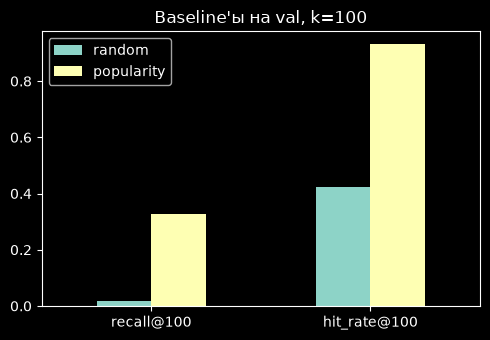

In [5]:
results.loc[RETRIEVAL_METRICS].plot.bar(figsize=(5, 3.5), rot=0)
plt.title("Baseline'ы на val, k=100")
plt.tight_layout()

Бонус: те же baseline'ы по метрикам итогового списка (k=10).

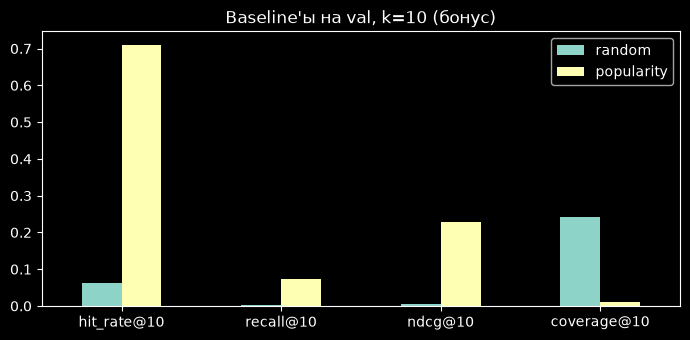

In [6]:
bonus_metrics = ["hit_rate@10", "recall@10", "ndcg@10", "coverage@10"]
results.loc[bonus_metrics].plot.bar(figsize=(7, 3.5), rot=0)
plt.title("Baseline'ы на val, k=10 (бонус)")
plt.tight_layout()

Вывод:

Мы видим, что отбор по популярности работает очень хорошо, у 71% пользователей среди первых 10 аниме есть хотя бы одно, которое он хотел бы посмотреть. Так и смотря на NDCG = 0.23 популярность выдаёт нужные аниме высоко в списке.

По всем метрикам случайность не находит почти ничего.

Следующие модели нужно сравнивать с популярностью по паре «точность и покрытие», а не только по точности. На val 173 пользователя, малые разницы между моделями могут быть шумом.

Попробуем следующие требования к модели: точность не ниже 90% от метрик популярности и покрытие должно быть хотя бы в 10 раз больше

То есть модель удачна, если ndcg@10 ≥ 0,206 и coverage@10 ≥ 0,119. Две оговорки, которые я тоже записала:

Важно:
- На val 173 человека, и разница в 10% точности лежит в пределах шума. Решать надо по доверительным интервалам, а не по одному числу.
- Покрытие на val не может быть выше 0,279 (173 человека × 10 мест на 6198 аниме), так что сравнивать можно только на одной и той же выборке.

Уточнение: эти пороги (`ndcg@10` и `coverage@10`) относятся к **итоговому списку** из 10 аниме, то есть к стадии реранжирования. Для моделей стадии retrieval главная метрика – `recall@100`: попали ли спрятанные ответы в кандидаты. Остальные метрики для retrieval смотрим как бонус и опираемся на них меньше.